# Mid-q structural motifs
Mid-q structural motif audit — 19 October 2026

Scope: 9,866 conformers across REST WT, ASTEROIDS WT/AA priors, IDPForge WT/AA and previous Jeffreys bAIes WT/AA. Common 121-residue constructs and existing canonical native PepsiSAXS predictions. New harmonic bAIes has no native SAXS yet and is not included here.

FINDINGS
1. A selected ASTEROIDS WT conformer (source index 365) matches REST index 486 at Rg 30.757 vs 30.369 A. Their native mid-q shapes, normalized at the grid point nearest q=.03, have log-RMS difference .02243. Buried nonlocal hydrophobic areas are 329 vs 1014 A^2; hydrophobic contact pairs are 3 vs 18. ASTEROIDS has 8 close antiparallel segment-chord pairs and greater anisotropy (.771 vs .571). It is an elongated, folded-back chain arrangement, rather than a densely packed hydrophobic core. See the PDBs and distance maps for exact geometry.
2. For WT coil pools, within-2A-Rg-bin ranked correlations with favorable infinitesimal mid-q enrichment are strongest for long-range CA pairs at 10–30A: IDPForge .755, bAIes .663, ASTEROIDS .829. Burial correlations are .579, .357, .549. ASTEROIDS anisotropy is .693. AA shows the same broad direction. These scores describe a perturbation around each uniform parent with its full-q scale fixed; they are not individual conformer fit scores and REST starts on a different side of the residual.
3. Broad chain reversals are not uniquely necessary. Removing 714 low-burial broad-reversal ASTEROIDS structures changes diagnostic SAXS-only mid-q chi2 from 34.95 to 37.11; Rg-matched random removals give 44.20 and 44.74. Removing the six structures with burial >=800 A^2 gives 36.66; six Rg-matched random removals give 35.89 and 35.88. This pool has multiple ways to supply useful distances; the broad reversal definition is too inclusive to identify a uniquely required motif.
4. The structural distinction to pursue is intermediate-distance crowding versus atomically tight packing. The example establishes an actual low-packing substitute for a packed conformer's native mid-q shape, and it belongs to the historical selected ASTEROIDS ensemble. Other example pairs are supplied, including candidates not selected historically.

METHODS
CA pair histograms: 1 A bins, sequence separations 1–6, 7–20, >20, all 121 residues including GP. Histograms count every unordered CA pair exactly once. The equal-weight CA Debye transform includes the self term; it is a geometric diagnostic, not a reconstruction of PepsiSAXS. Direct unbinned checks are recorded in validation.json. Representative heavy-atom P(r) uses ZiZj electron-count weights, normalized by all heavy-atom pair weight; no hydrogen, solvent, or q-dependent form factors. It is explicitly a structural fingerprint.
Packing metrics reuse the previous audit: nonlocal sidechain C/S surface burial outside +/-6 residues; 1.4 A probe; 240 SASA sphere points; hydrophobic contact cutoff 5 A, sequence separation >6. No structures were rebuilt.
Broad reversal metric: 10-residue chords starting every 5 residues; sequence-start separation >=20; chord dot product <-.7 and midpoint distance <20 A. It counts overlapping segment pairs, not independent hairpins. Local heterogeneity is the coefficient of variation of 20-residue window Rg, sampled every 5 residues. Anisotropy is relative shape anisotropy from the CA gyration tensor.
Native matching: REST burial >800 and ASTEROIDS <400 A^2, AST Rg 24–32 A, paired Rg difference <1 A; minimize RMS log native I(q)/I(qnear .03) difference over .08<q<.25. Three examples use distinct REST indices. These thresholds are exploratory and recorded, not fitted to experimental residuals. Shape normalization is labeled separately from experimental scaling.
Removal fits: same validated Borthakur SAXS-only engine and fixed REST-derived SEM as the prior diagnostic comparisons; one optimized global scale, no offset, Kish absolute Neff >=200 for all ASTEROIDS conditions. Random-removal controls match removed counts within each 2 A Rg bin, seeds17/29. These diagnostic fits are separate from the historical ASTEROIDS selection and the combined CS/SAXS fits. All fit curve/weights checks, gradients and primal/dual checks passed. Occasional Apple BLAS warning messages were followed by independent finite einsum verification.

DATA/PROVENANCE
analyze.py reads manifests and verified coordinate/prediction caches from Ensemble_Comparison_121_2026-10-15 and Hydrophobic_SAXS_audit_2026-10-16. conformer_ids in each distance_scattering NPZ match metric rows and native curve columns. Representative PDB source paths and SHA256 hashes are recorded in representatives/provenance.json. No prior results or weights were modified.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
p=Path.cwd()
display(pd.read_csv(p/'ablation_results.csv'))
display(pd.read_csv(p/'matched_REST_ASTEROIDS.csv').head(10))


,experiment,N,Neff,chi2_mid,chi2_all
0,AST_WT_baseline,2000,200.001329,34.950819,10.375481
1,AST_WT_control_broad_reversals_low_burial_17,1286,200.000492,44.197093,13.700079
2,AST_WT_control_broad_reversals_low_burial_29,1286,200.001303,44.739263,13.882721
3,AST_WT_control_high_burial_17,1994,200.000463,35.886850,10.707903
4,AST_WT_control_high_burial_29,1994,200.000752,35.884761,10.708733
5,AST_WT_remove_broad_reversals_low_burial,1286,200.001187,37.114559,11.418267
6,AST_WT_remove_high_burial,1994,200.000373,36.657292,10.841364


,REST_index,AST_index,log_midq_shape_RMS,REST_Rg,AST_Rg,REST_HSA,AST_HSA
0,486,365,0.022435,30.369226,30.756990,1013.70465,329.34830
1,490,633,0.042722,29.127155,28.822327,814.71380,285.75275
2,373,839,0.044085,23.962317,24.778864,1006.63110,387.45908
3,57,1615,0.046943,23.830791,24.026283,900.73250,328.38058
4,490,1122,0.049862,29.127155,28.375580,814.71380,253.70776
5,330,277,0.051684,26.153812,25.514760,969.96060,327.70563
6,490,207,0.053587,29.127155,28.935188,814.71380,336.80035
7,57,802,0.055488,23.830791,24.757664,900.73250,389.47784
8,330,214,0.057566,26.153812,26.404194,969.96060,364.01904
9,490,395,0.058544,29.127155,29.538342,814.71380,238.16759


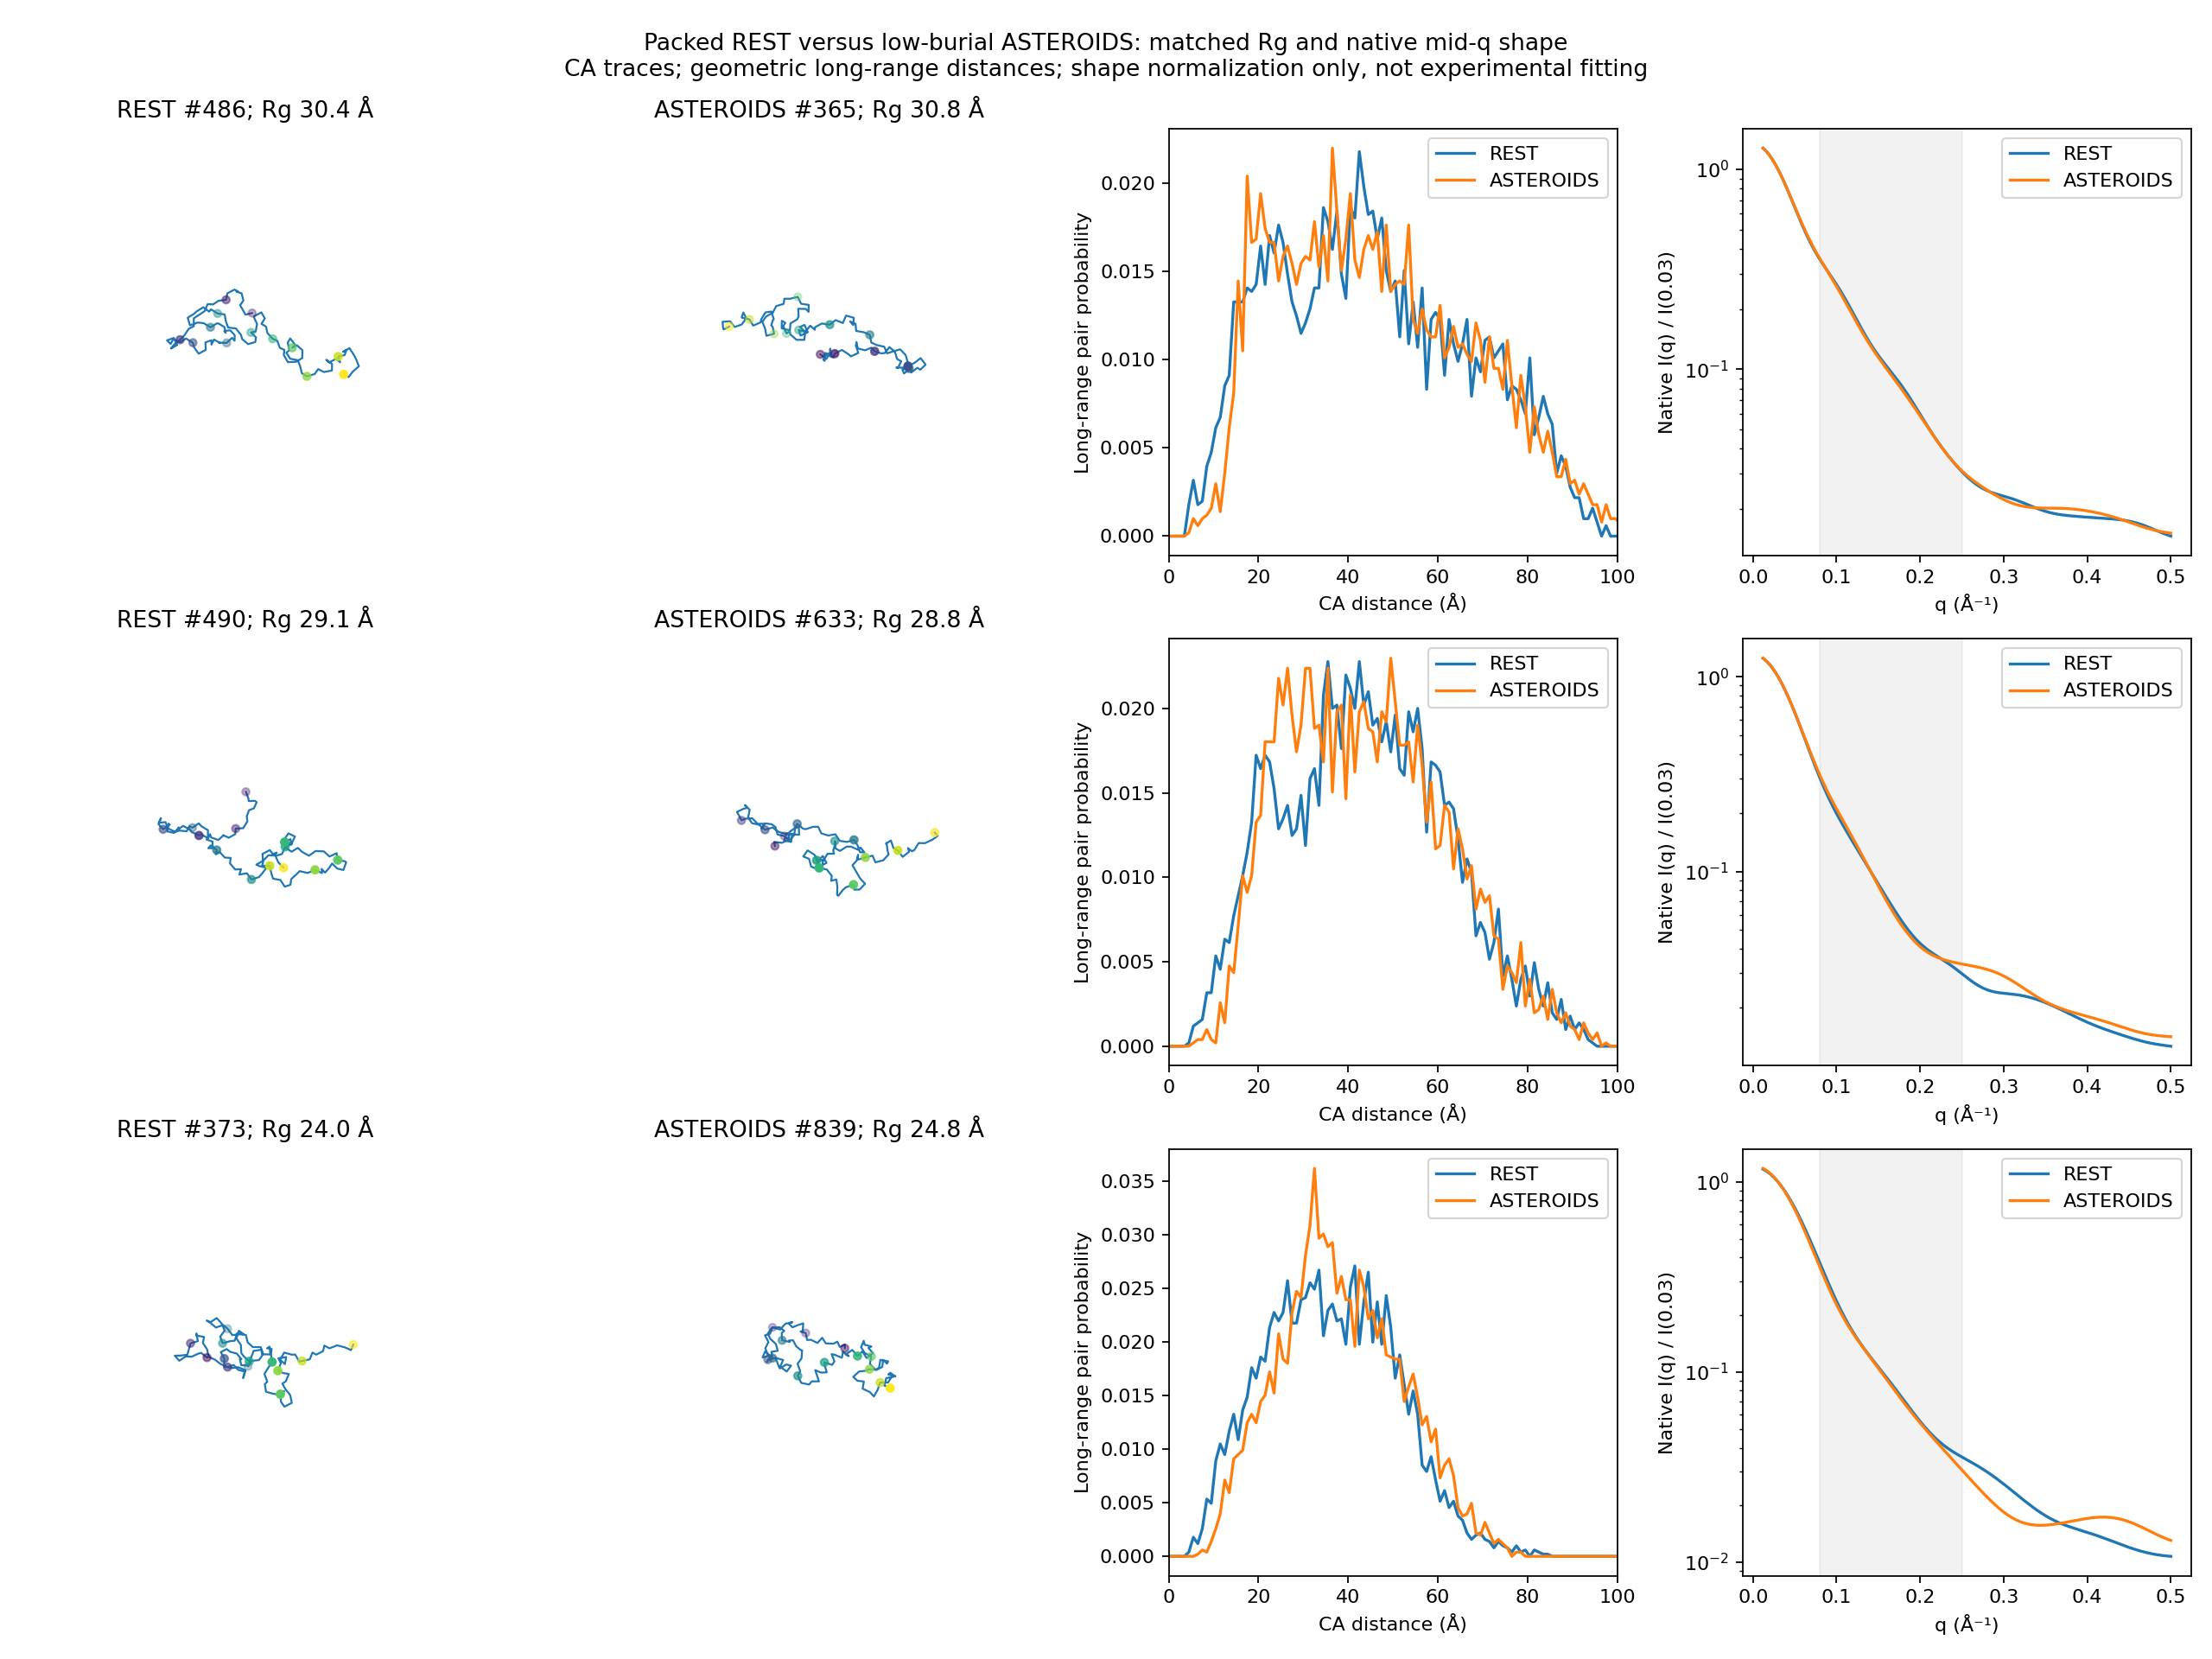

In [2]:
display(Image(filename=str(p/'matched_motifs.png')))

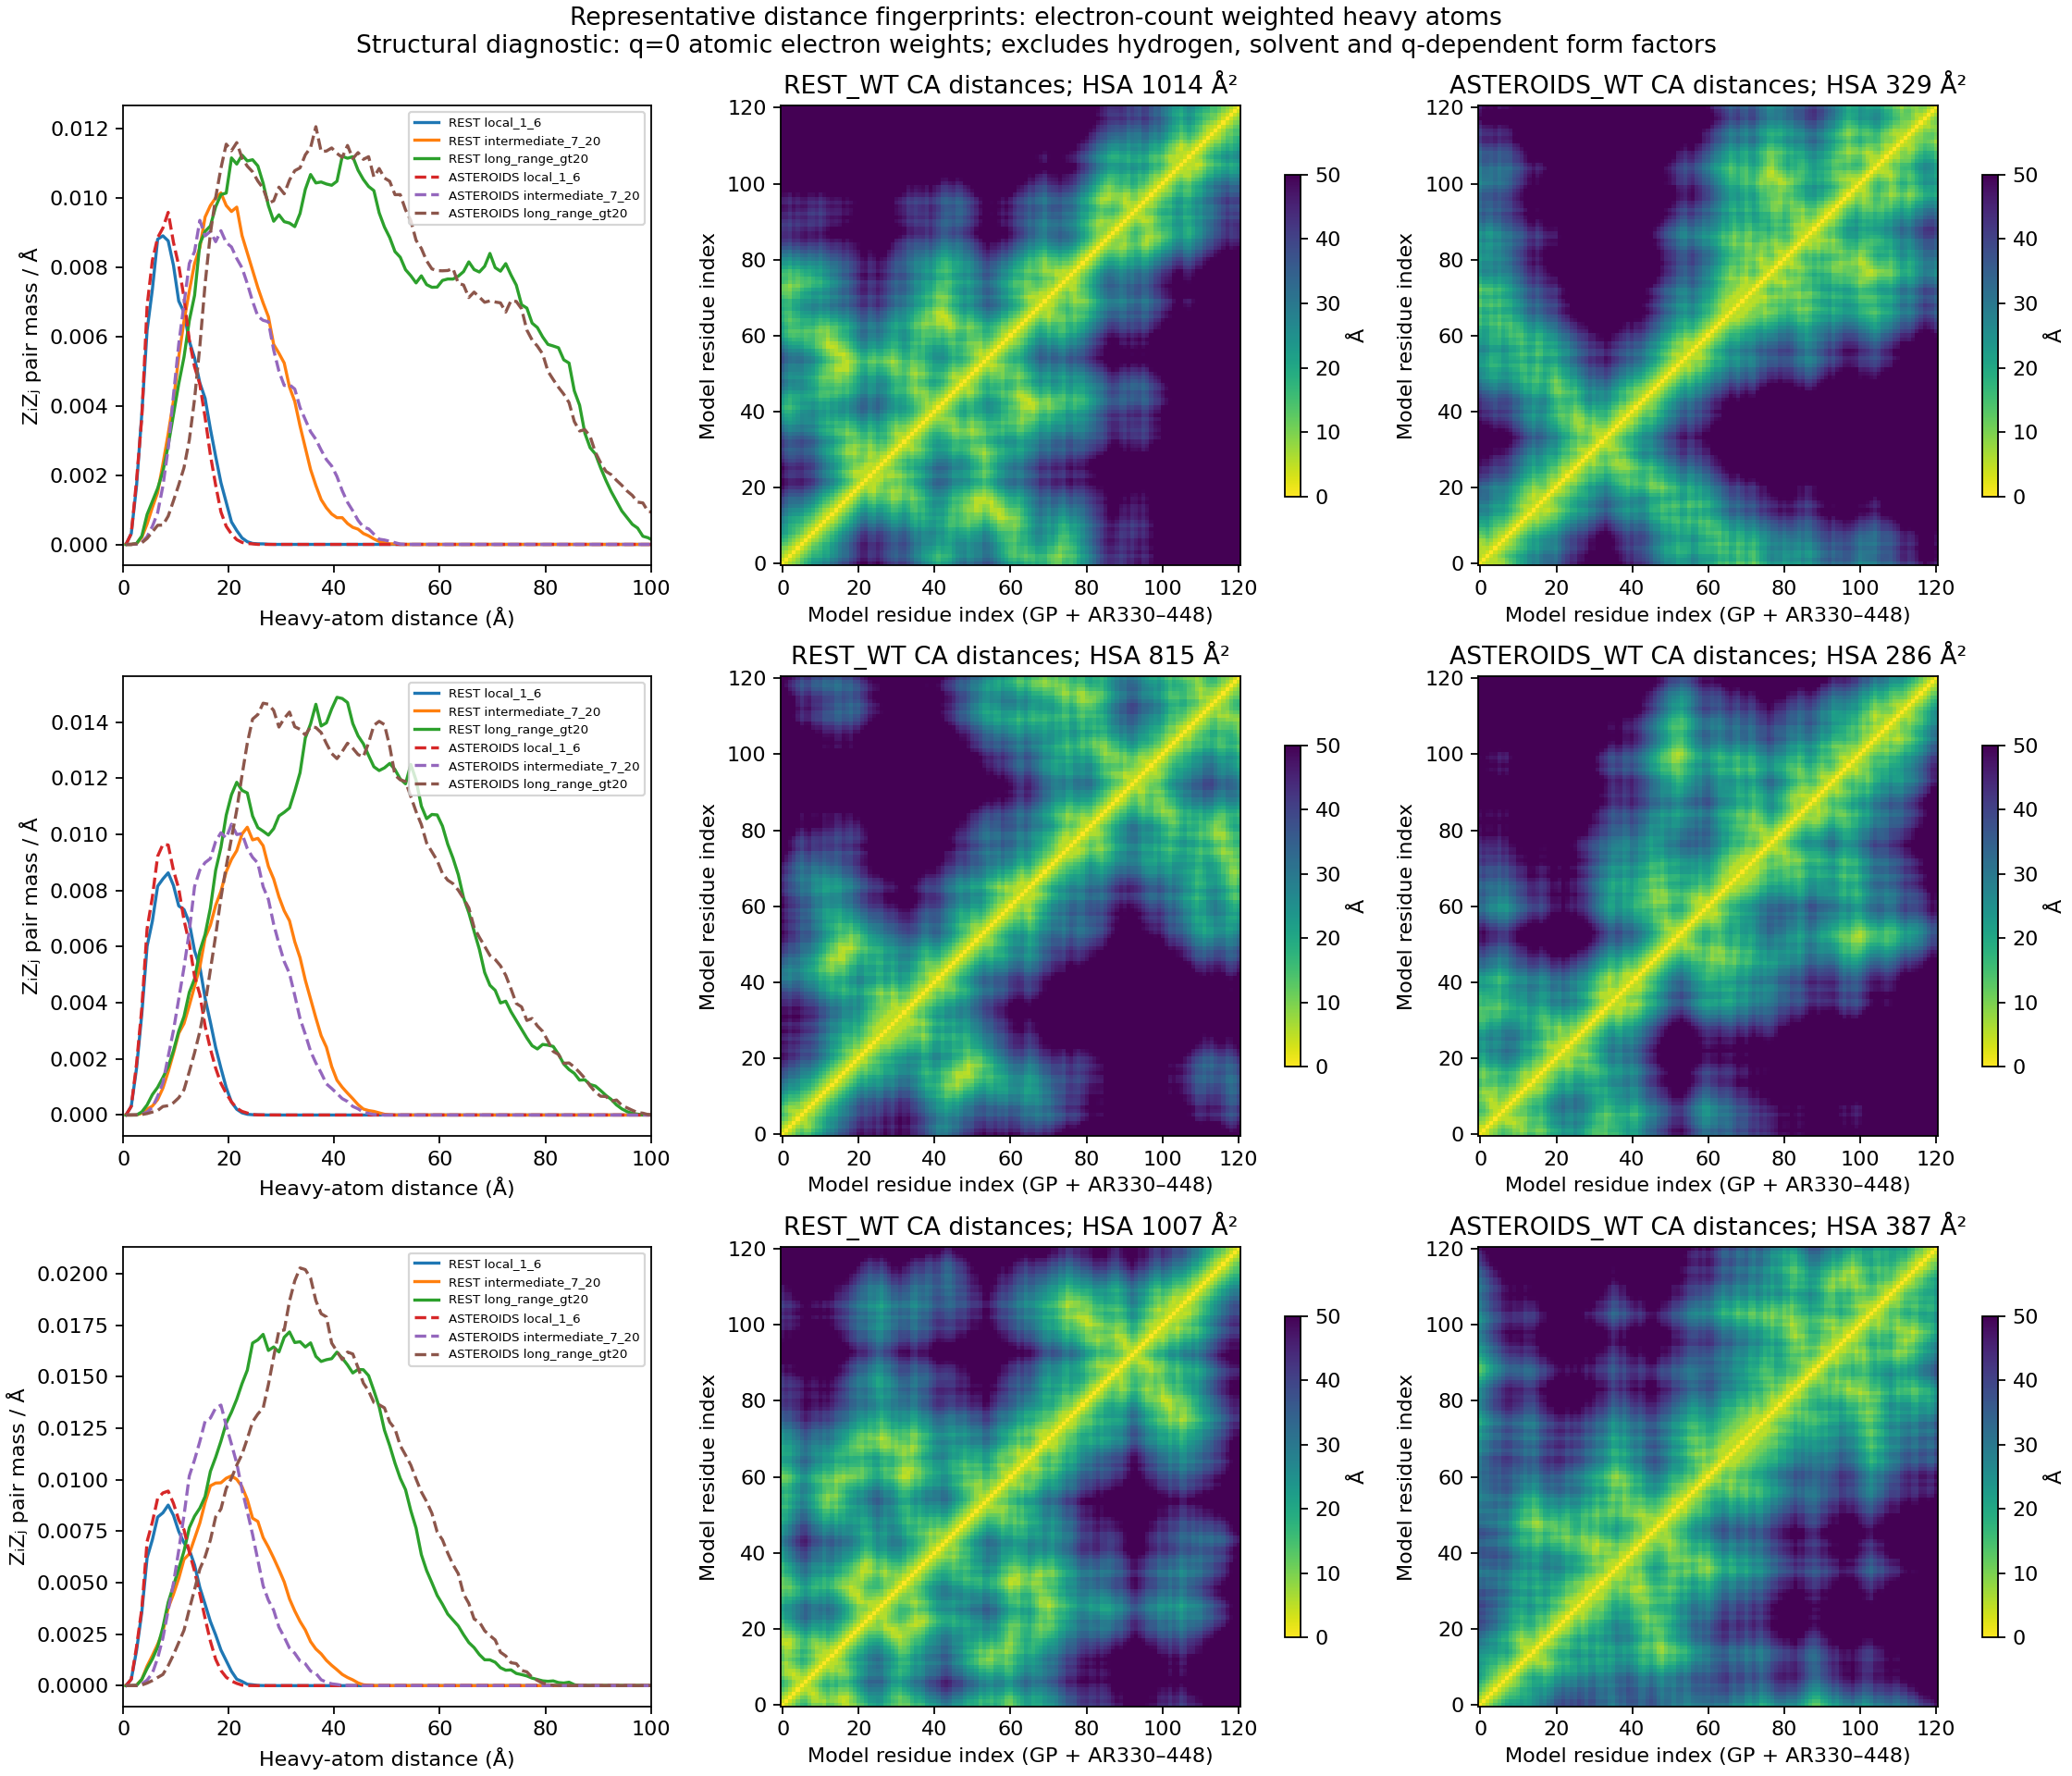

In [3]:
display(Image(filename=str(p/'representative_distance_fingerprints.png')))

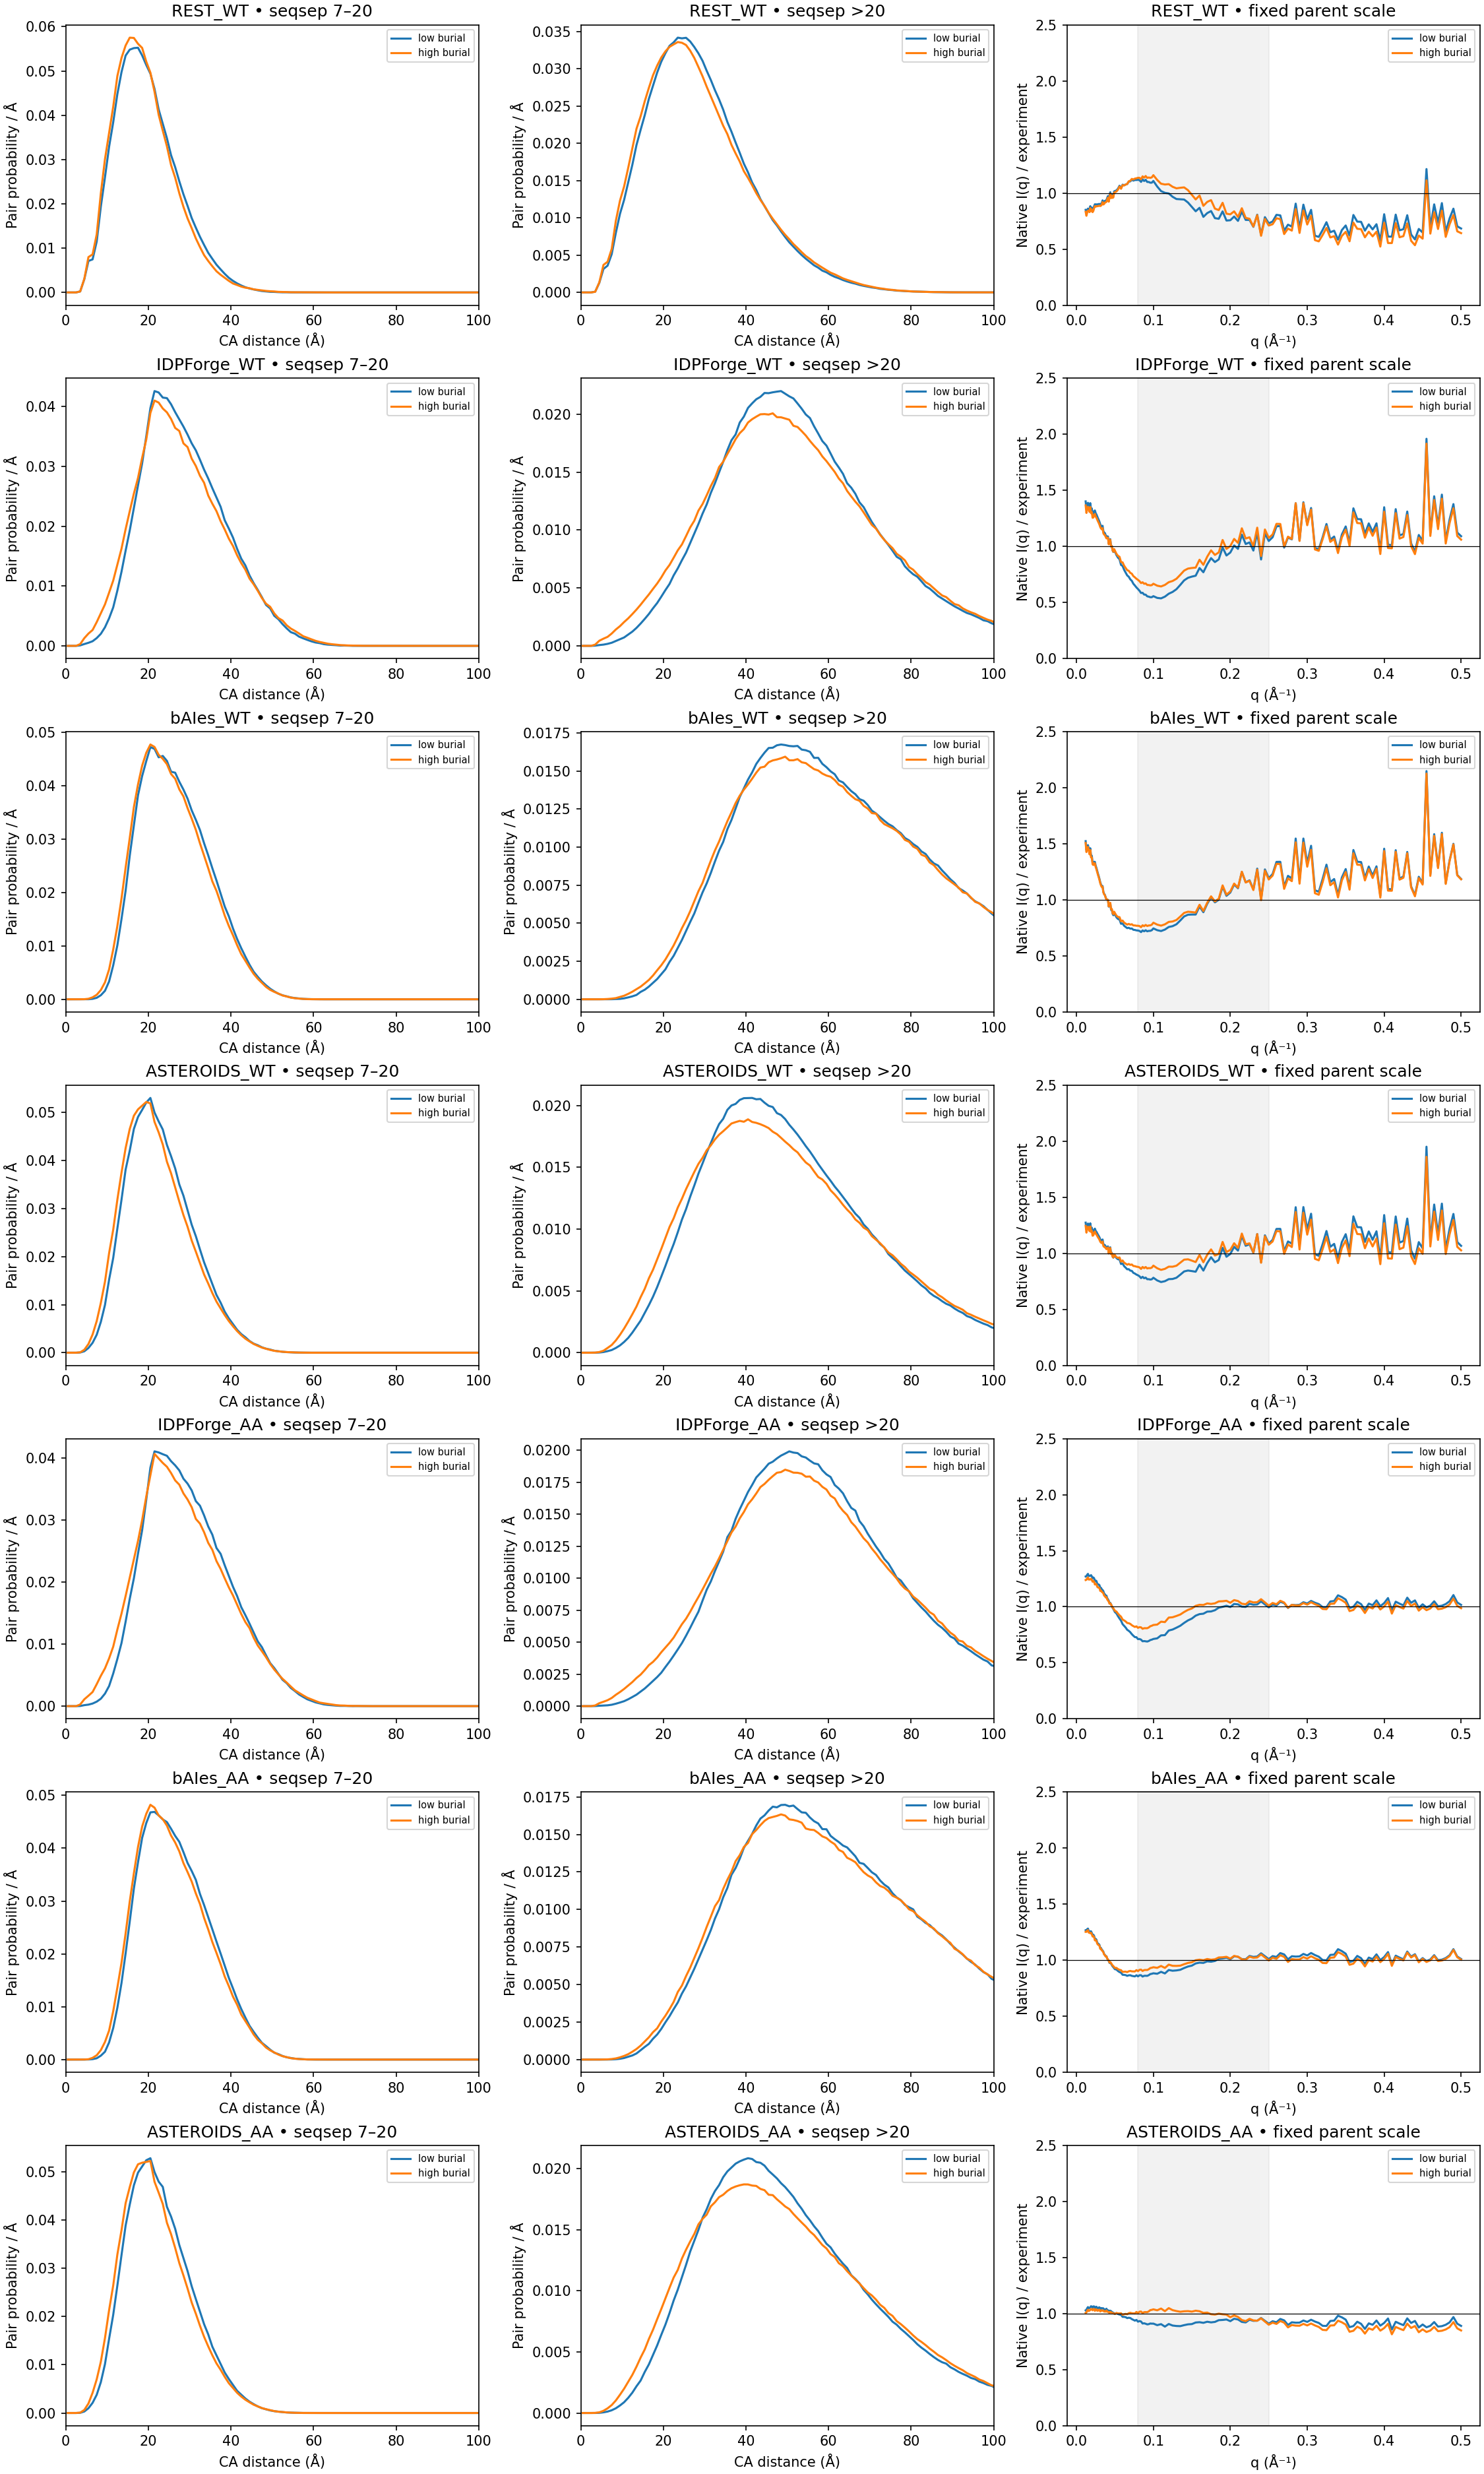

In [4]:
display(Image(filename=str(p/'burial_distance_midq.png')))

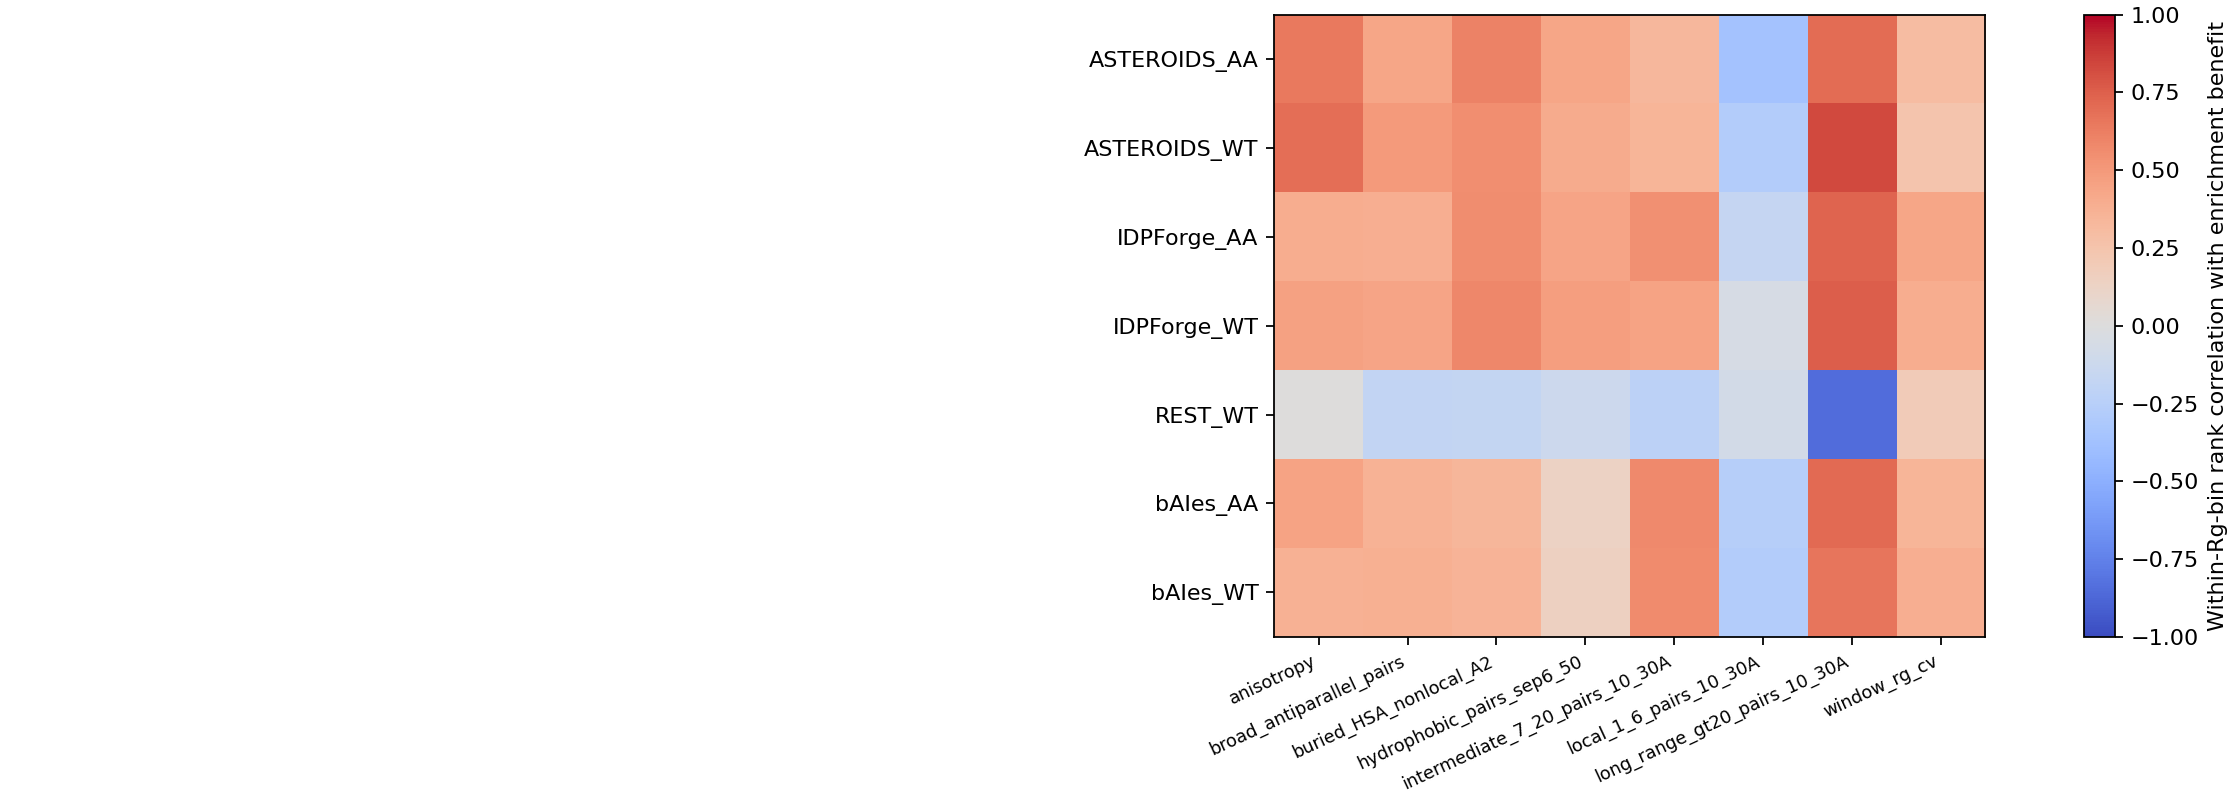

In [5]:
display(Image(filename=str(p/'feature_correlations.png')))

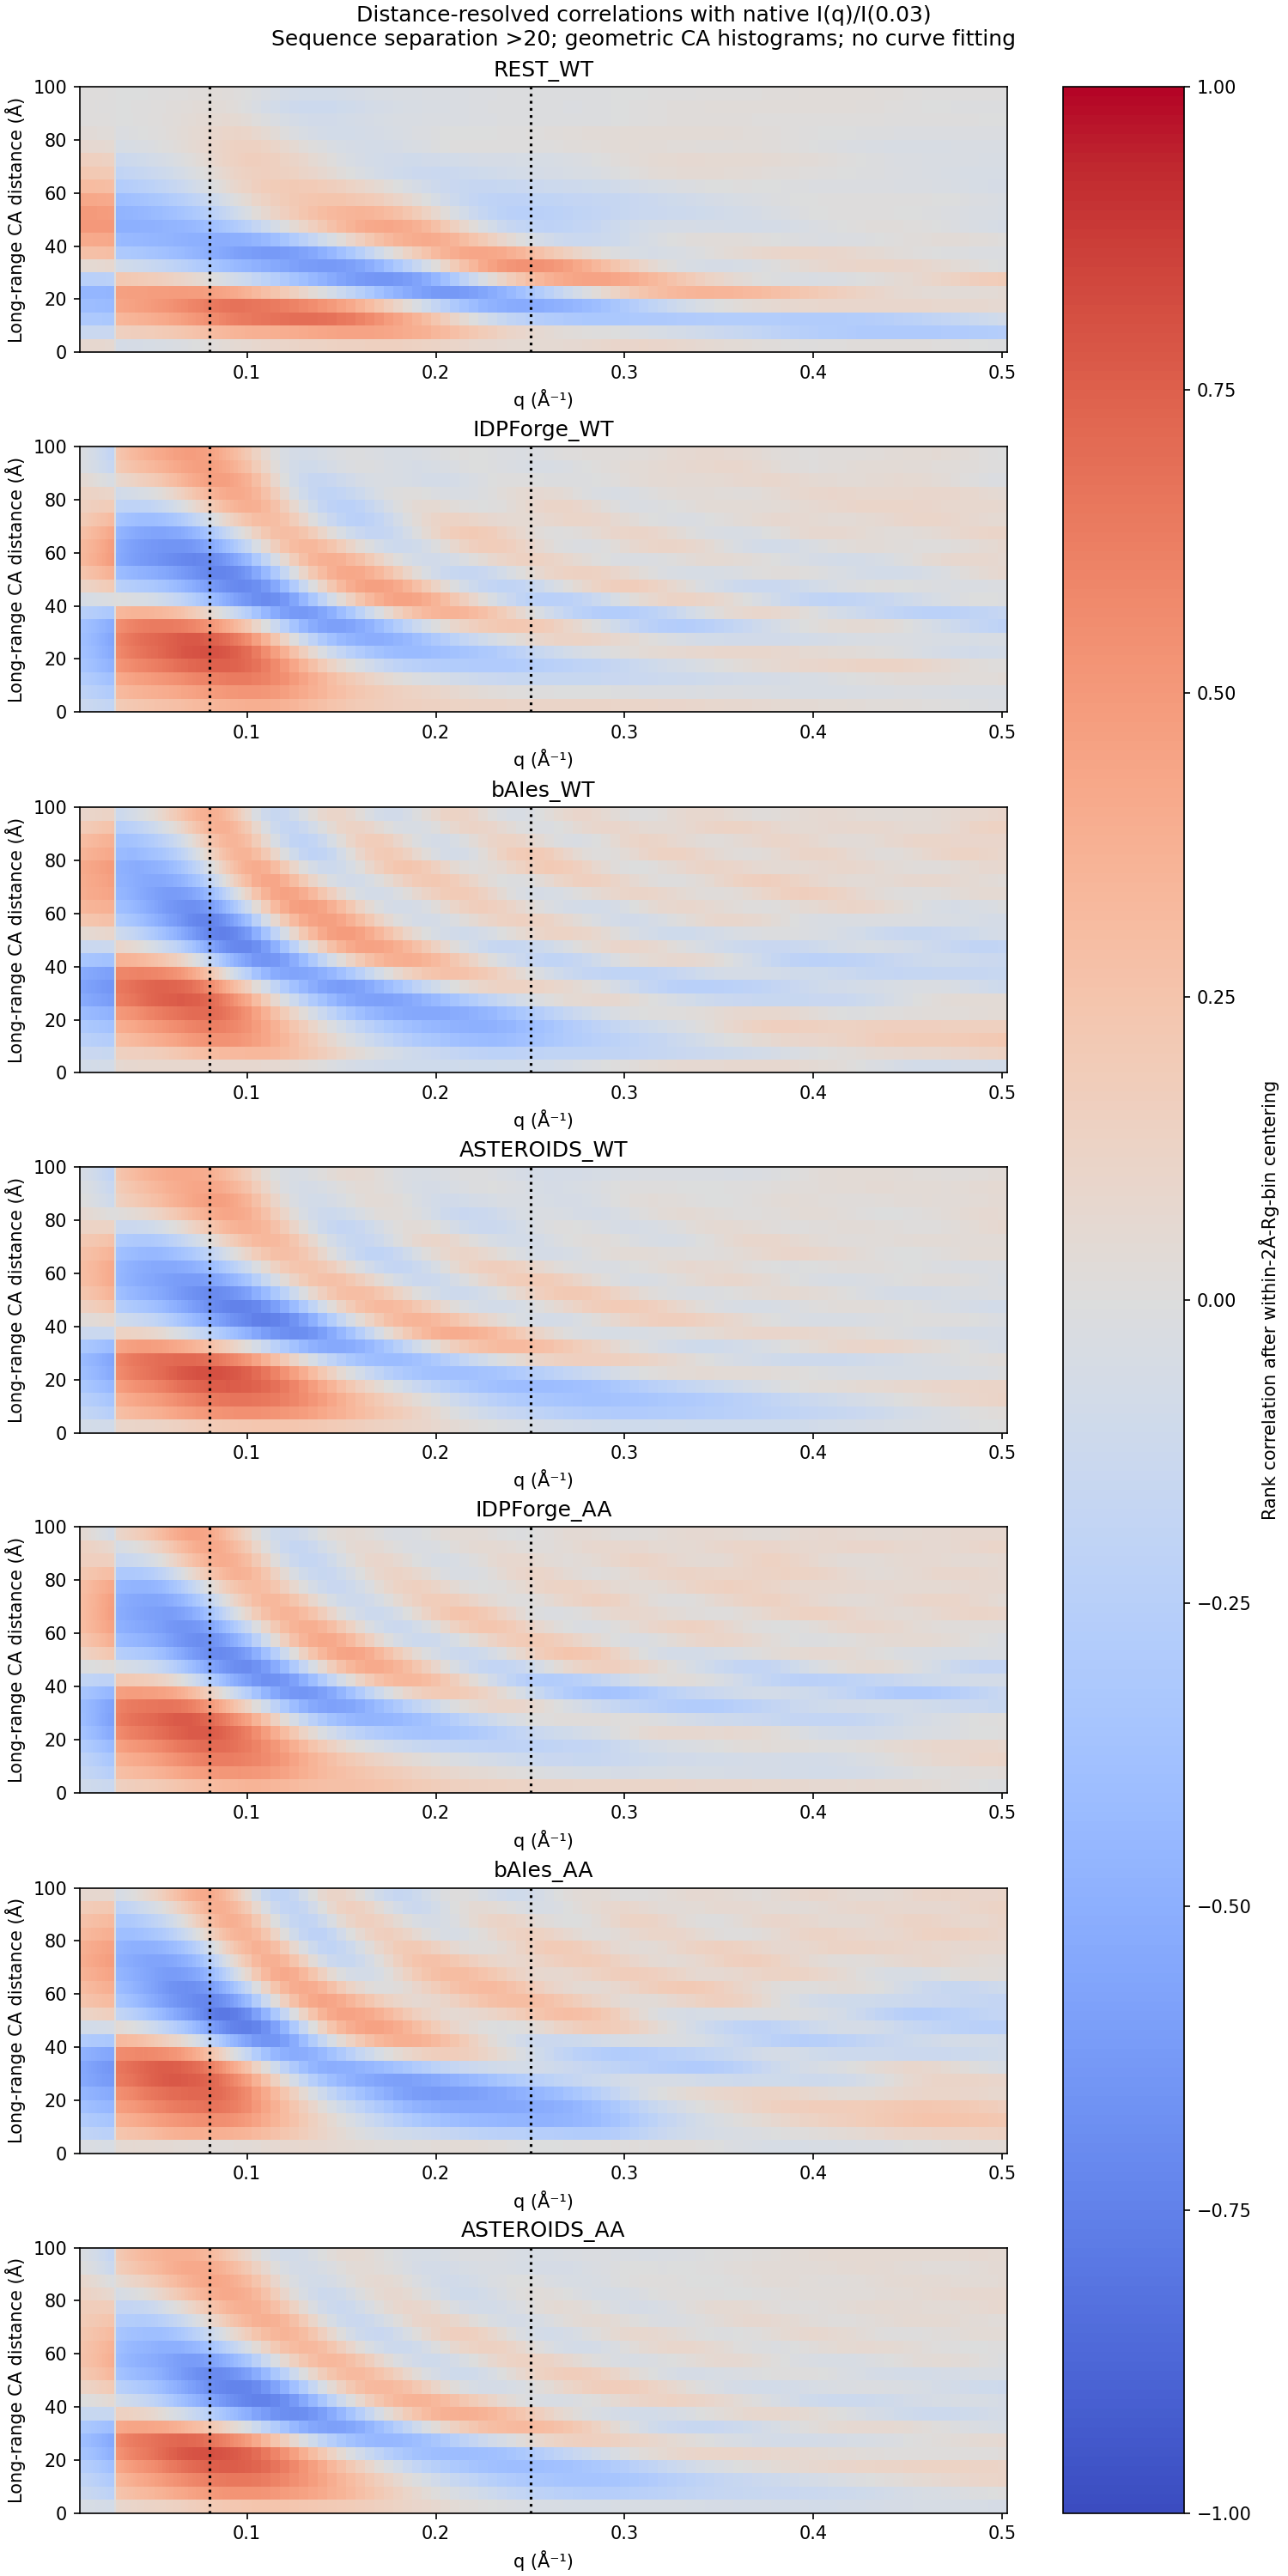

In [6]:
display(Image(filename=str(p/'distance_q_correlations.png')))